In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['font.family'] = 'serif'
plt.rcParams['mathtext.fontset'] = 'dejavuserif'
plt.rcParams['font.size'] = 12

# Exercise 1

Simpson rule: 1.718284154699897
Analytical: 1.718281828459045
Error: 0.000135 %



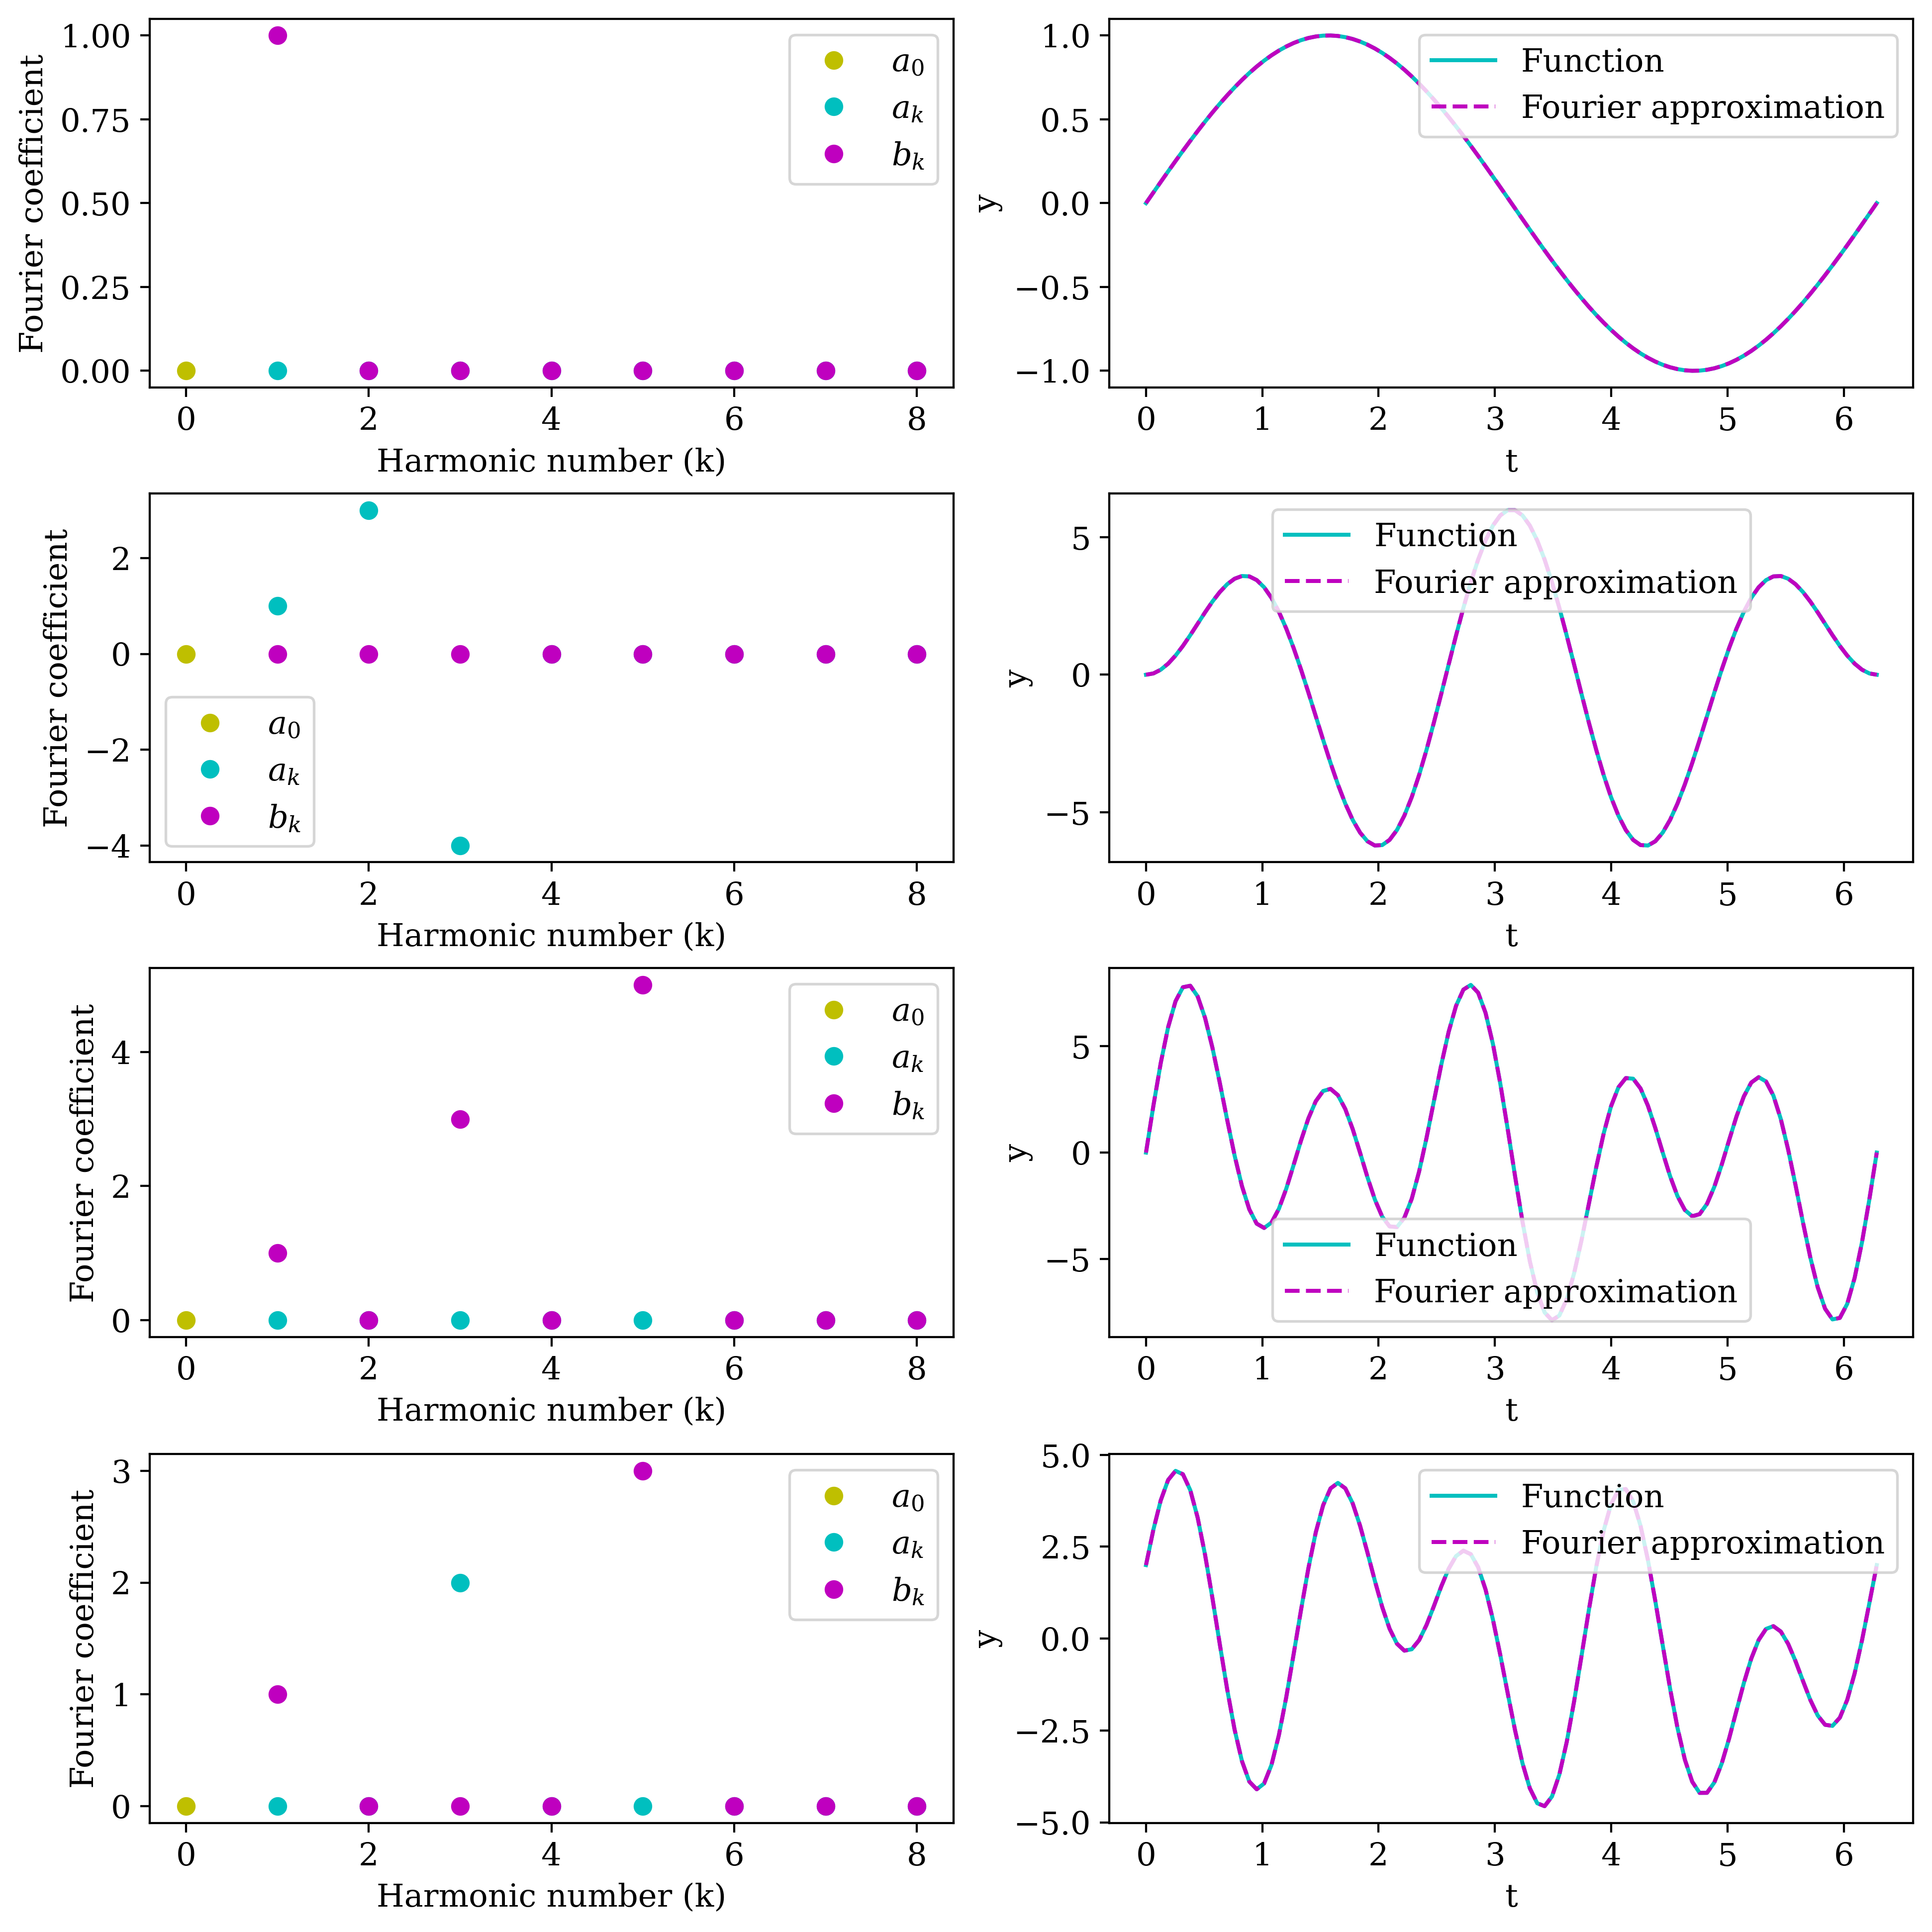

In [2]:
"""Simpson's rule for integration of functions

f - function to integrate
a, b - integration limits
n - number of intervals (must be even)
"""
def simpson(f, a, b, n):
  h = (b - a) / n

  return (h / 3) \
          * (f(a) + 2 * sum(f(a + 2 * j * h) for j in range(1, n//2))
          + 4 * sum(f(a + (2 * j - 1) * h) for j in range(1, n//2 + 1))
          + f(b))


result = simpson(np.exp, 0, 1, 8)
G = np.e - 1

print(f'Simpson rule: {result}')
print(f'Analytical: {G}')
print(f'Error: {100 * np.abs(result - (G)) / (G):.3} %\n')


"""a0 term of Fourier series for function f

f - function to integrate
T - period of f
n - number of intervals for the simpson function (must be even)
"""
def a_0(f, ω, n):
  T = 2 * np.pi / ω
  return (1 / T) * simpson(f, 0, T, n)


"""ak term of Fourier series for function f

f - function to integrate
T - period of f
ω - angular frequency
k - harmonic number (>0)
n - number of intervals for the simpson function (must be even)
"""
def a_k(f, ω, k, n):
  T = 2 * np.pi / ω
  F = lambda t: f(t) * np.cos(k * ω * t)
  return (2 / T) * simpson(F, 0, T, n)


"""bk term of Fourier series for function f

f - function to integrate
T - period of f
ω - angular frequency
k - harmonic number (>0)
n - number of intervals for the simpson function (must be even)
"""
def b_k(f, ω, k, n):
  T = 2 * np.pi / ω
  F = lambda t: f(t) * np.sin(k * ω * t)
  return (2 / T) * simpson(F, 0, T, n)


"""Fourier series approximation of function f

f - function to integrate
T - period of f
ω - angular frequency
n - number of intervals for the simpson function (must be even)
t - time to evaluate the series
lim - number of terms to use in the series
"""
def fourier_series(f, ω, n, t, lim):
  return a_0(f, ω, n) + sum(a_k(f, ω, k, n) * np.cos(k * ω * t)
                            + b_k(f, ω, k, n) * np.sin(k * ω * t)
                            for k in range(1, lim + 1))


"""Plot Fourier coefficients and function approximations

f - function to integrate
ω - angular frequency
n - number of intervals for the simpson function (must be even)
k - harmonic number (>0)
lim - number of terms to use in the series
ax - array of axes to plot on
"""
def plot_compare(f, ω, n, k, lim, ax):
  ks = np.arange(1, k+1)

  ax[0].plot(0, a_0(f, ω, n), 'yo', label='$a_0$')
  ax[0].plot(ks, [a_k(f, ω, k, n) for k in ks], 'co', label='$a_k$')
  ax[0].plot(ks, [b_k(f, ω, k, n) for k in ks], 'mo', label='$b_k$')
  ax[0].set_xlabel('Harmonic number (k)')
  ax[0].set_ylabel('Fourier coefficient')
  ax[0].legend()

  ts = np.linspace(0, 2 * np.pi / ω, num=100)
  ys_approx = fourier_series(f, ω, n, ts, lim)

  ax[1].plot(ts, f(ts), label='Function', color='c')
  ax[1].plot(ts, ys_approx, 'm--', label='Fourier approximation')
  ax[1].set_xlabel('t')
  ax[1].set_ylabel('y')
  ax[1].legend()


ω = 1

funcs = [lambda t: np.sin(ω * t),
         lambda t: np.cos(ω * t) + 3 * np.cos(2 * ω * t)
         - 4 * np.cos(3 * ω * t),
         lambda t: np.sin(ω * t) + 3 * np.sin(3 * ω * t)
         + 5 * np.sin(5 * ω * t),
         lambda t: np.sin(ω * t) + 2 * np.cos(3 * ω * t)
         + 3 * np.sin(5 * ω * t)]

fig, axs = plt.subplots(4, 2, figsize=(10, 10), constrained_layout=True,
                        dpi=384)

for F, ax in zip(funcs, axs):
  plot_compare(F, ω, 50, 8, 10, ax)

plt.savefig('compare.png', bbox_inches='tight')
plt.show()

# Exercise 2

k=1, a=0.03, b=1.27, true b=1.27
k=2, a=-0.00, b=-0.00, true b=0.00
k=3, a=0.03, b=0.42, true b=0.42
k=4, a=0.00, b=0.00, true b=0.00
k=5, a=0.03, b=0.25, true b=0.25




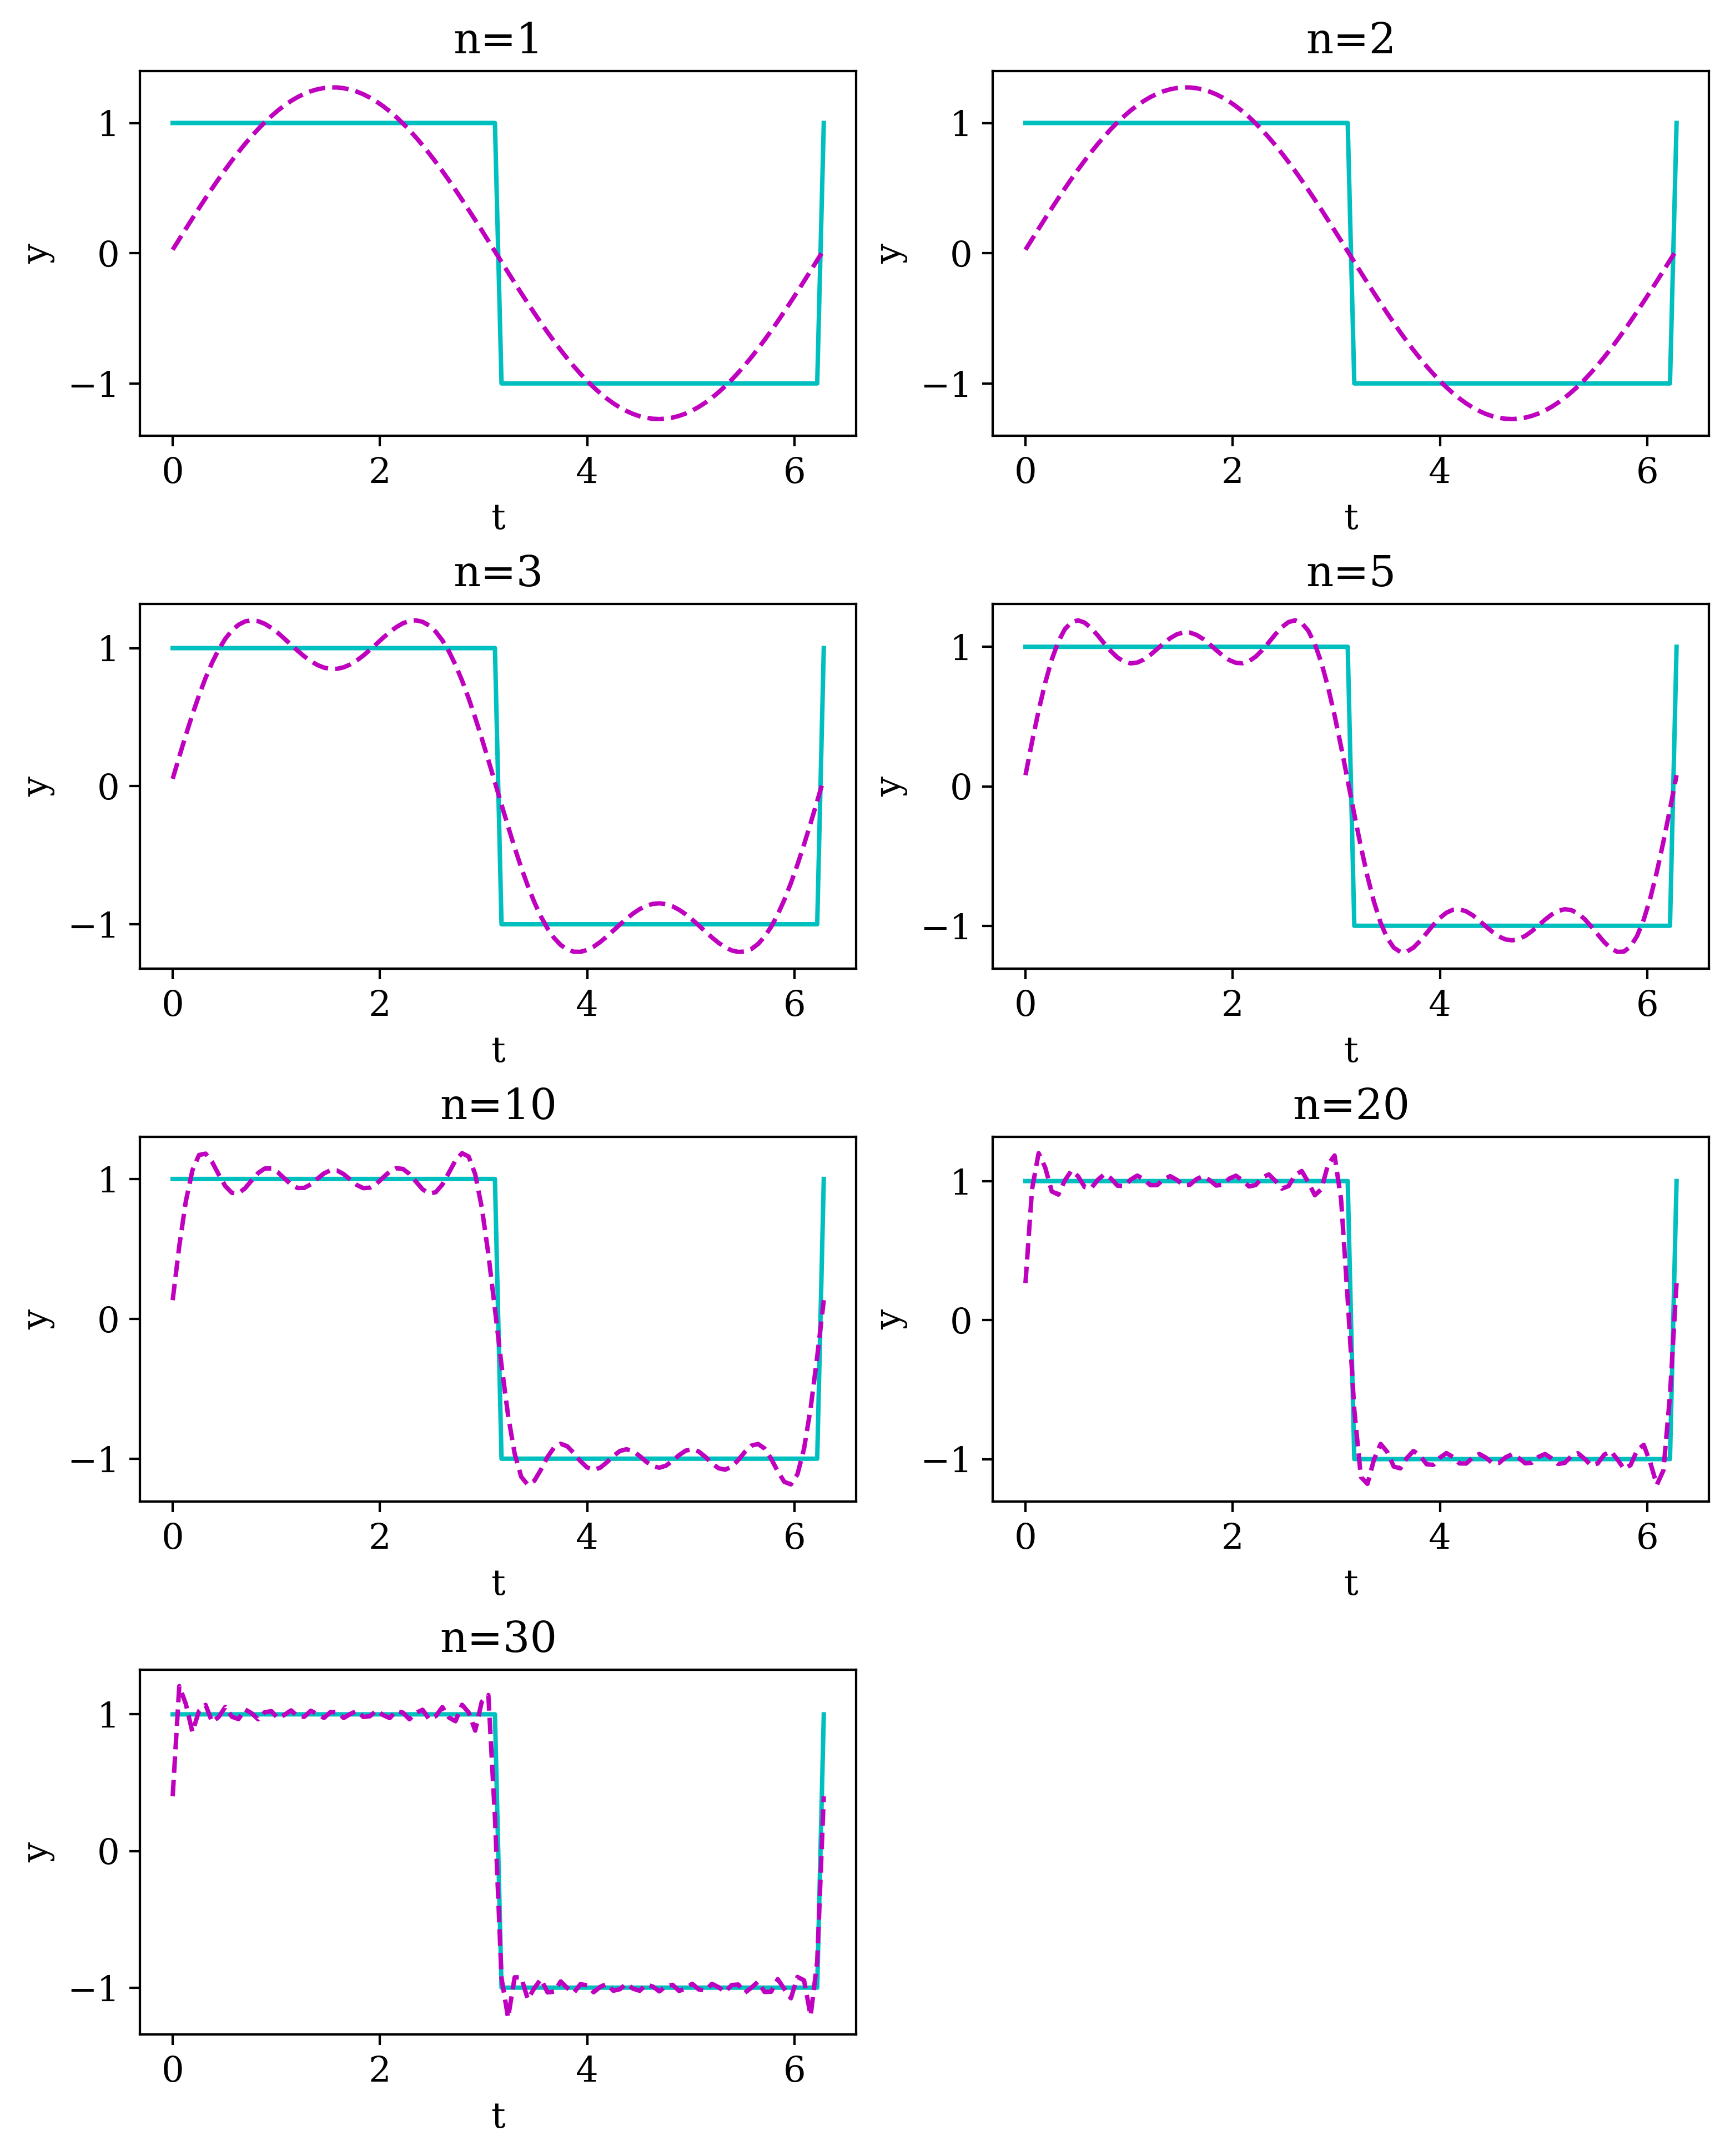


a0=-0.68, true a0=-0.68
k=1, a=0.54, true a=0.54, b=0.28, true b=0.29
k=2, a=0.31, true a=0.29, b=0.44, true b=0.45
k=3, a=0.05, true a=0.03, b=0.42, true b=0.42
k=4, a=-0.10, true a=-0.12, b=0.27, true b=0.26
k=5, a=-0.11, true a=-0.12, b=0.10, true b=0.09




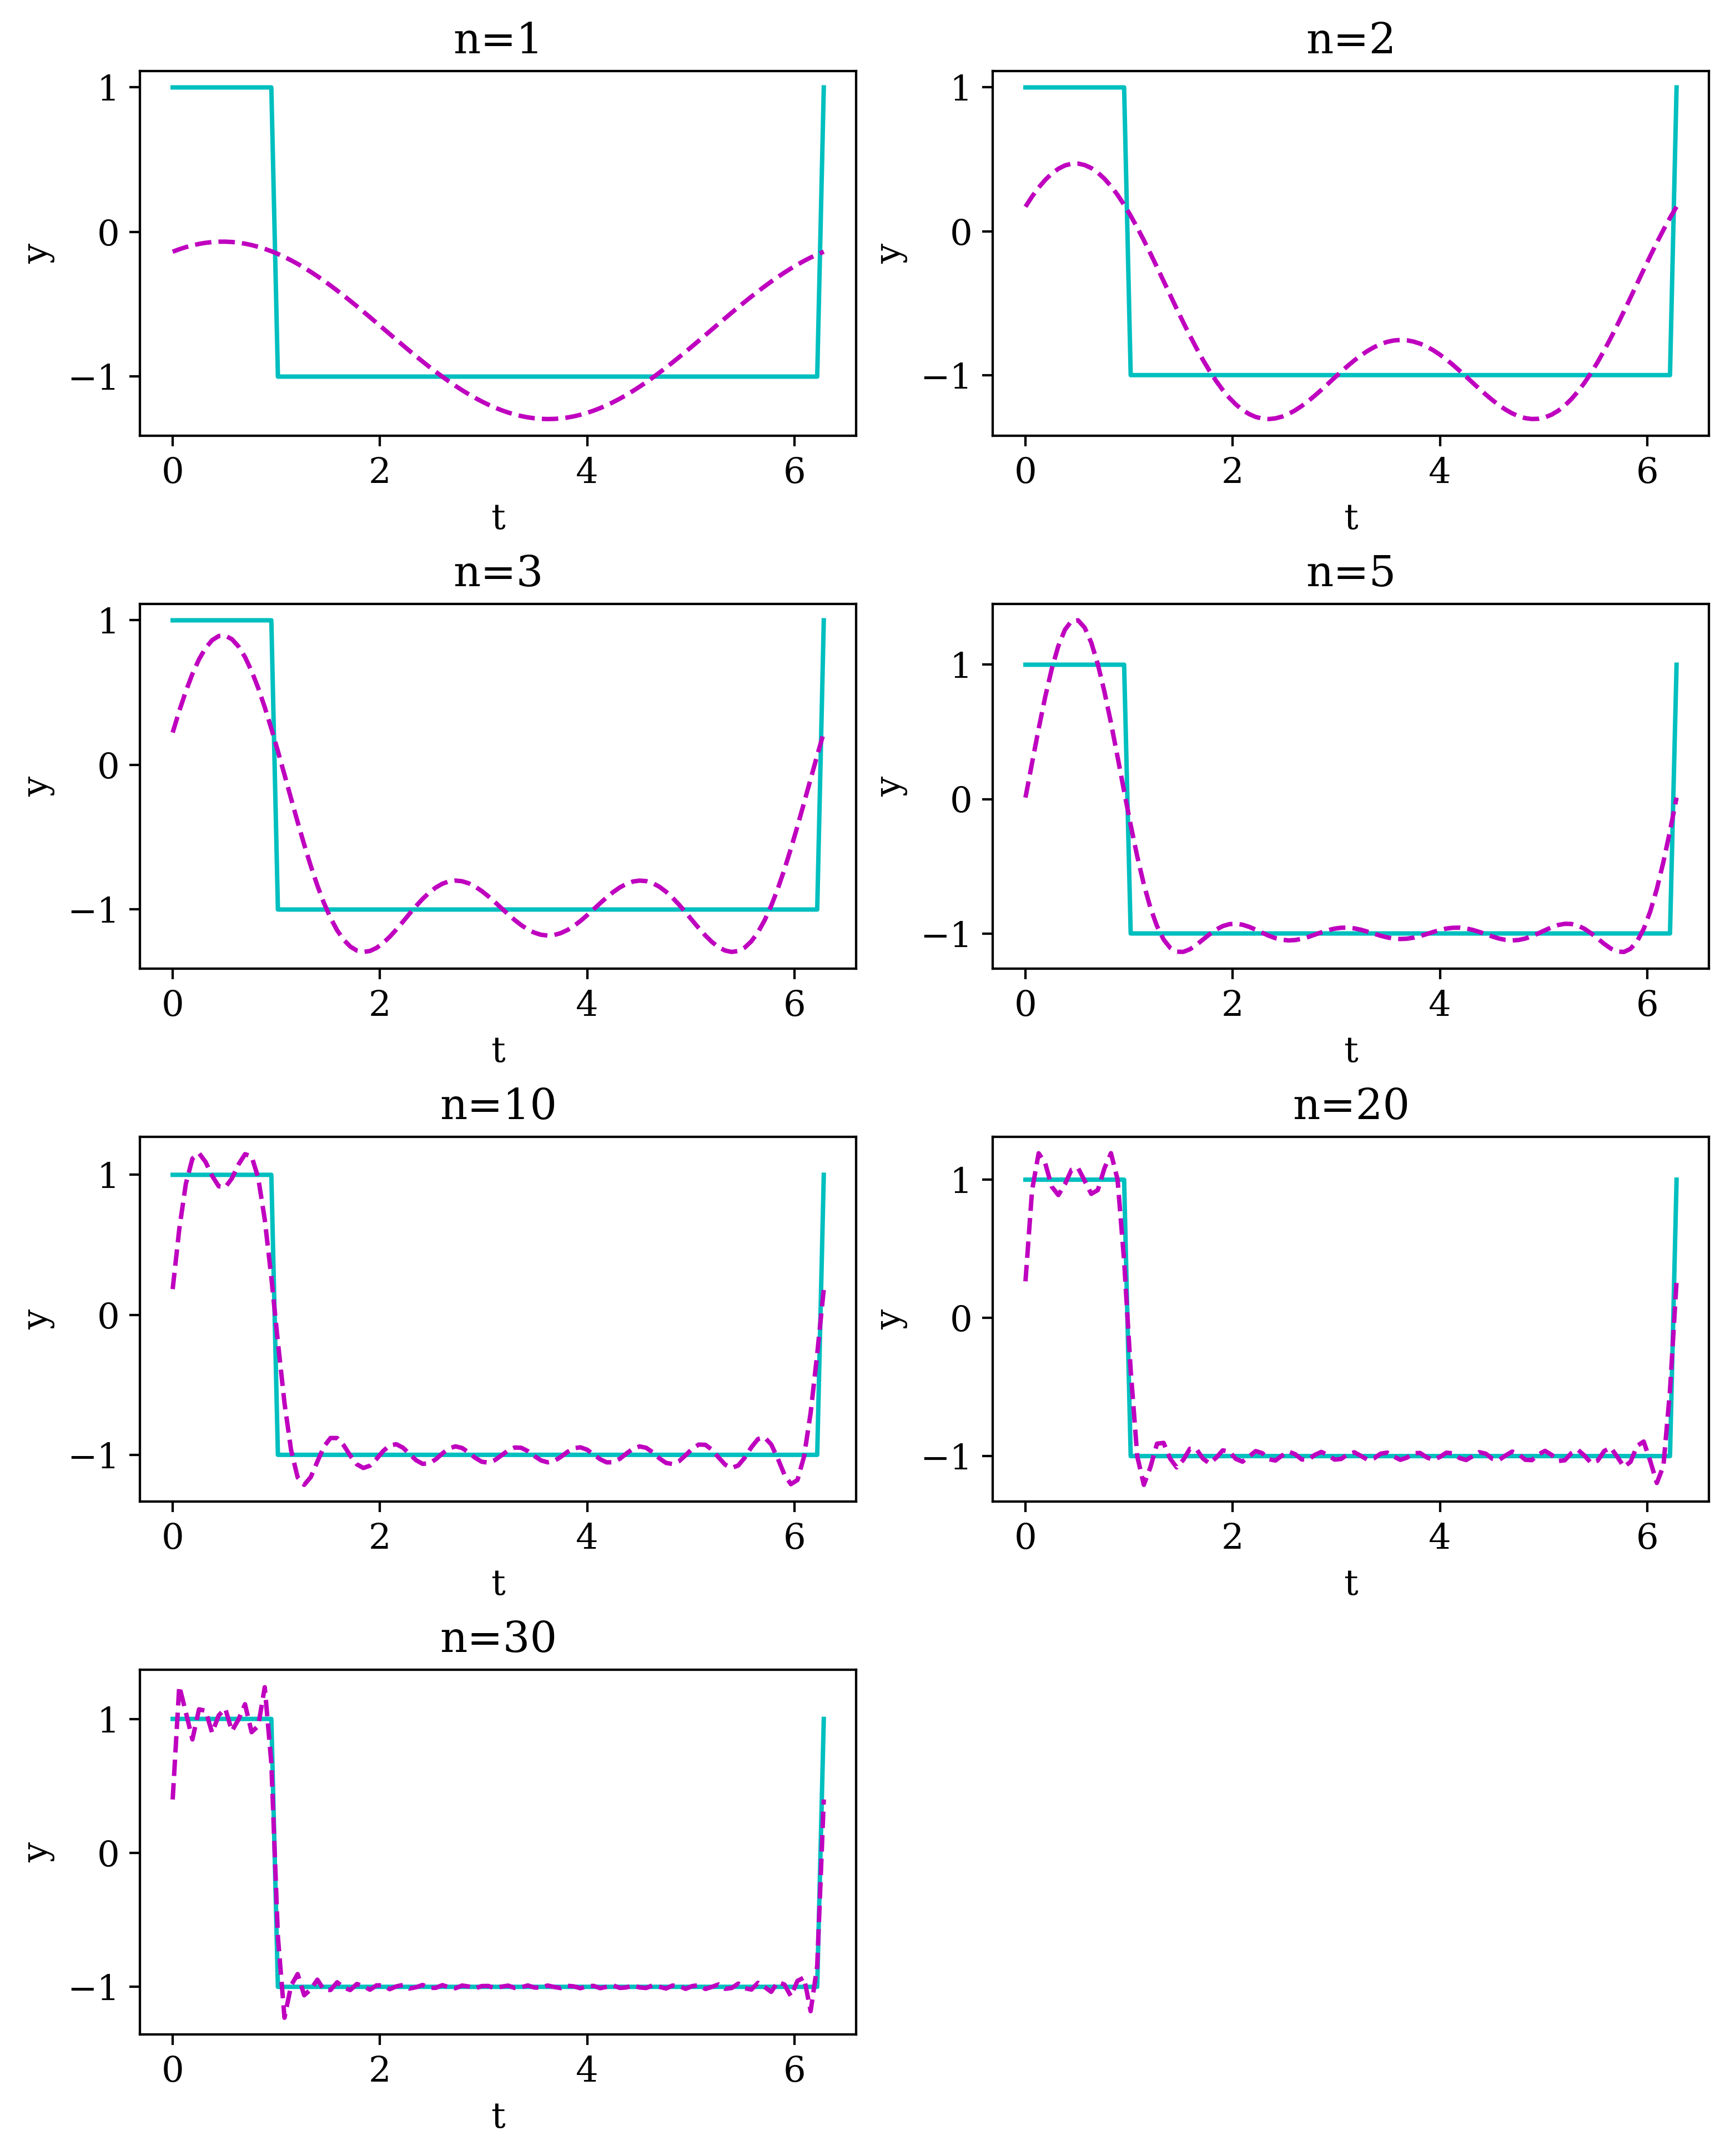

In [3]:
"""Square wave function

t - time
ω - angular frequency
"""
def square_wave(t, ω=1):
  θ = (ω * t) % (2 * np.pi)

  return 1 if θ <= np.pi else -1


n = 100

for k in range(1, 6):
  true_bk = 0 if k % 2 == 0 else 4 / (np.pi * k)

  print(f'k={k}, a={a_k(square_wave, ω, k, n):.2f}, '
  f'b={b_k(square_wave, ω, k, n):.2f}, true b={true_bk:.2f}')

print('\n')

ts = np.linspace(0, 2 * np.pi, 100)


"""Plot wave function and its Fourier series approximation

wave - function to integrate
name - name of the plot
ω - angular frequency
"""
def plot_wave(wave, name, n, ω=1):
  lims = [1, 2, 3, 5, 10, 20, 30]

  fig, axs = plt.subplots(4, 2, figsize=(8, 10), constrained_layout=True,
                          dpi=384)

  for lim, ax in zip(lims, axs.flat):
    ys_approx = [fourier_series(wave, ω, n, t, lim) for t in ts]

    ax.plot(ts, [wave(t) for t in ts], color='c')
    ax.plot(ts, ys_approx, 'm--')
    ax.set_xlabel('t')
    ax.set_ylabel('y')
    ax.set_title(f'n={lim}')

  fig.delaxes(axs[3,1])
  plt.savefig(f'{name}.png', bbox_inches='tight')
  plt.show()


plot_wave(square_wave, 'square_wave', n)


"""Rectangular wave function

t - time
τ - shape
ω - angular frequency
"""
def rectangular_wave(t, τ=1, ω=1):
  θ = (ω * t) % (2 * np.pi)

  return 1 if θ < ω * τ else -1


τ = 1
α = 2 * np.pi / (ω * τ)
true_a0 = (2 / α) - 1

print(f'\na0={a_0(rectangular_wave, ω, n):.2f}, '
      f'true a0={true_a0:.2f}')

for k in range(1, 6):
  true_ak = (2 / (k * np.pi)) * np.sin(2 * k * np.pi / α)
  true_bk = (2 / (k * np.pi)) * (1 - np.cos(2 * k * np.pi / α))

  print(f'k={k}, a={a_k(rectangular_wave, ω, k, n):.2f}, '
  f'true a={true_ak:.2f}, '
  f'b={b_k(rectangular_wave, ω, k, n):.2f}, '
  f'true b={true_bk:.2f}')

print('\n')

plot_wave(rectangular_wave, 'rectangular_wave', n)

# Exercise 3

r=10.0, v1=0.078125



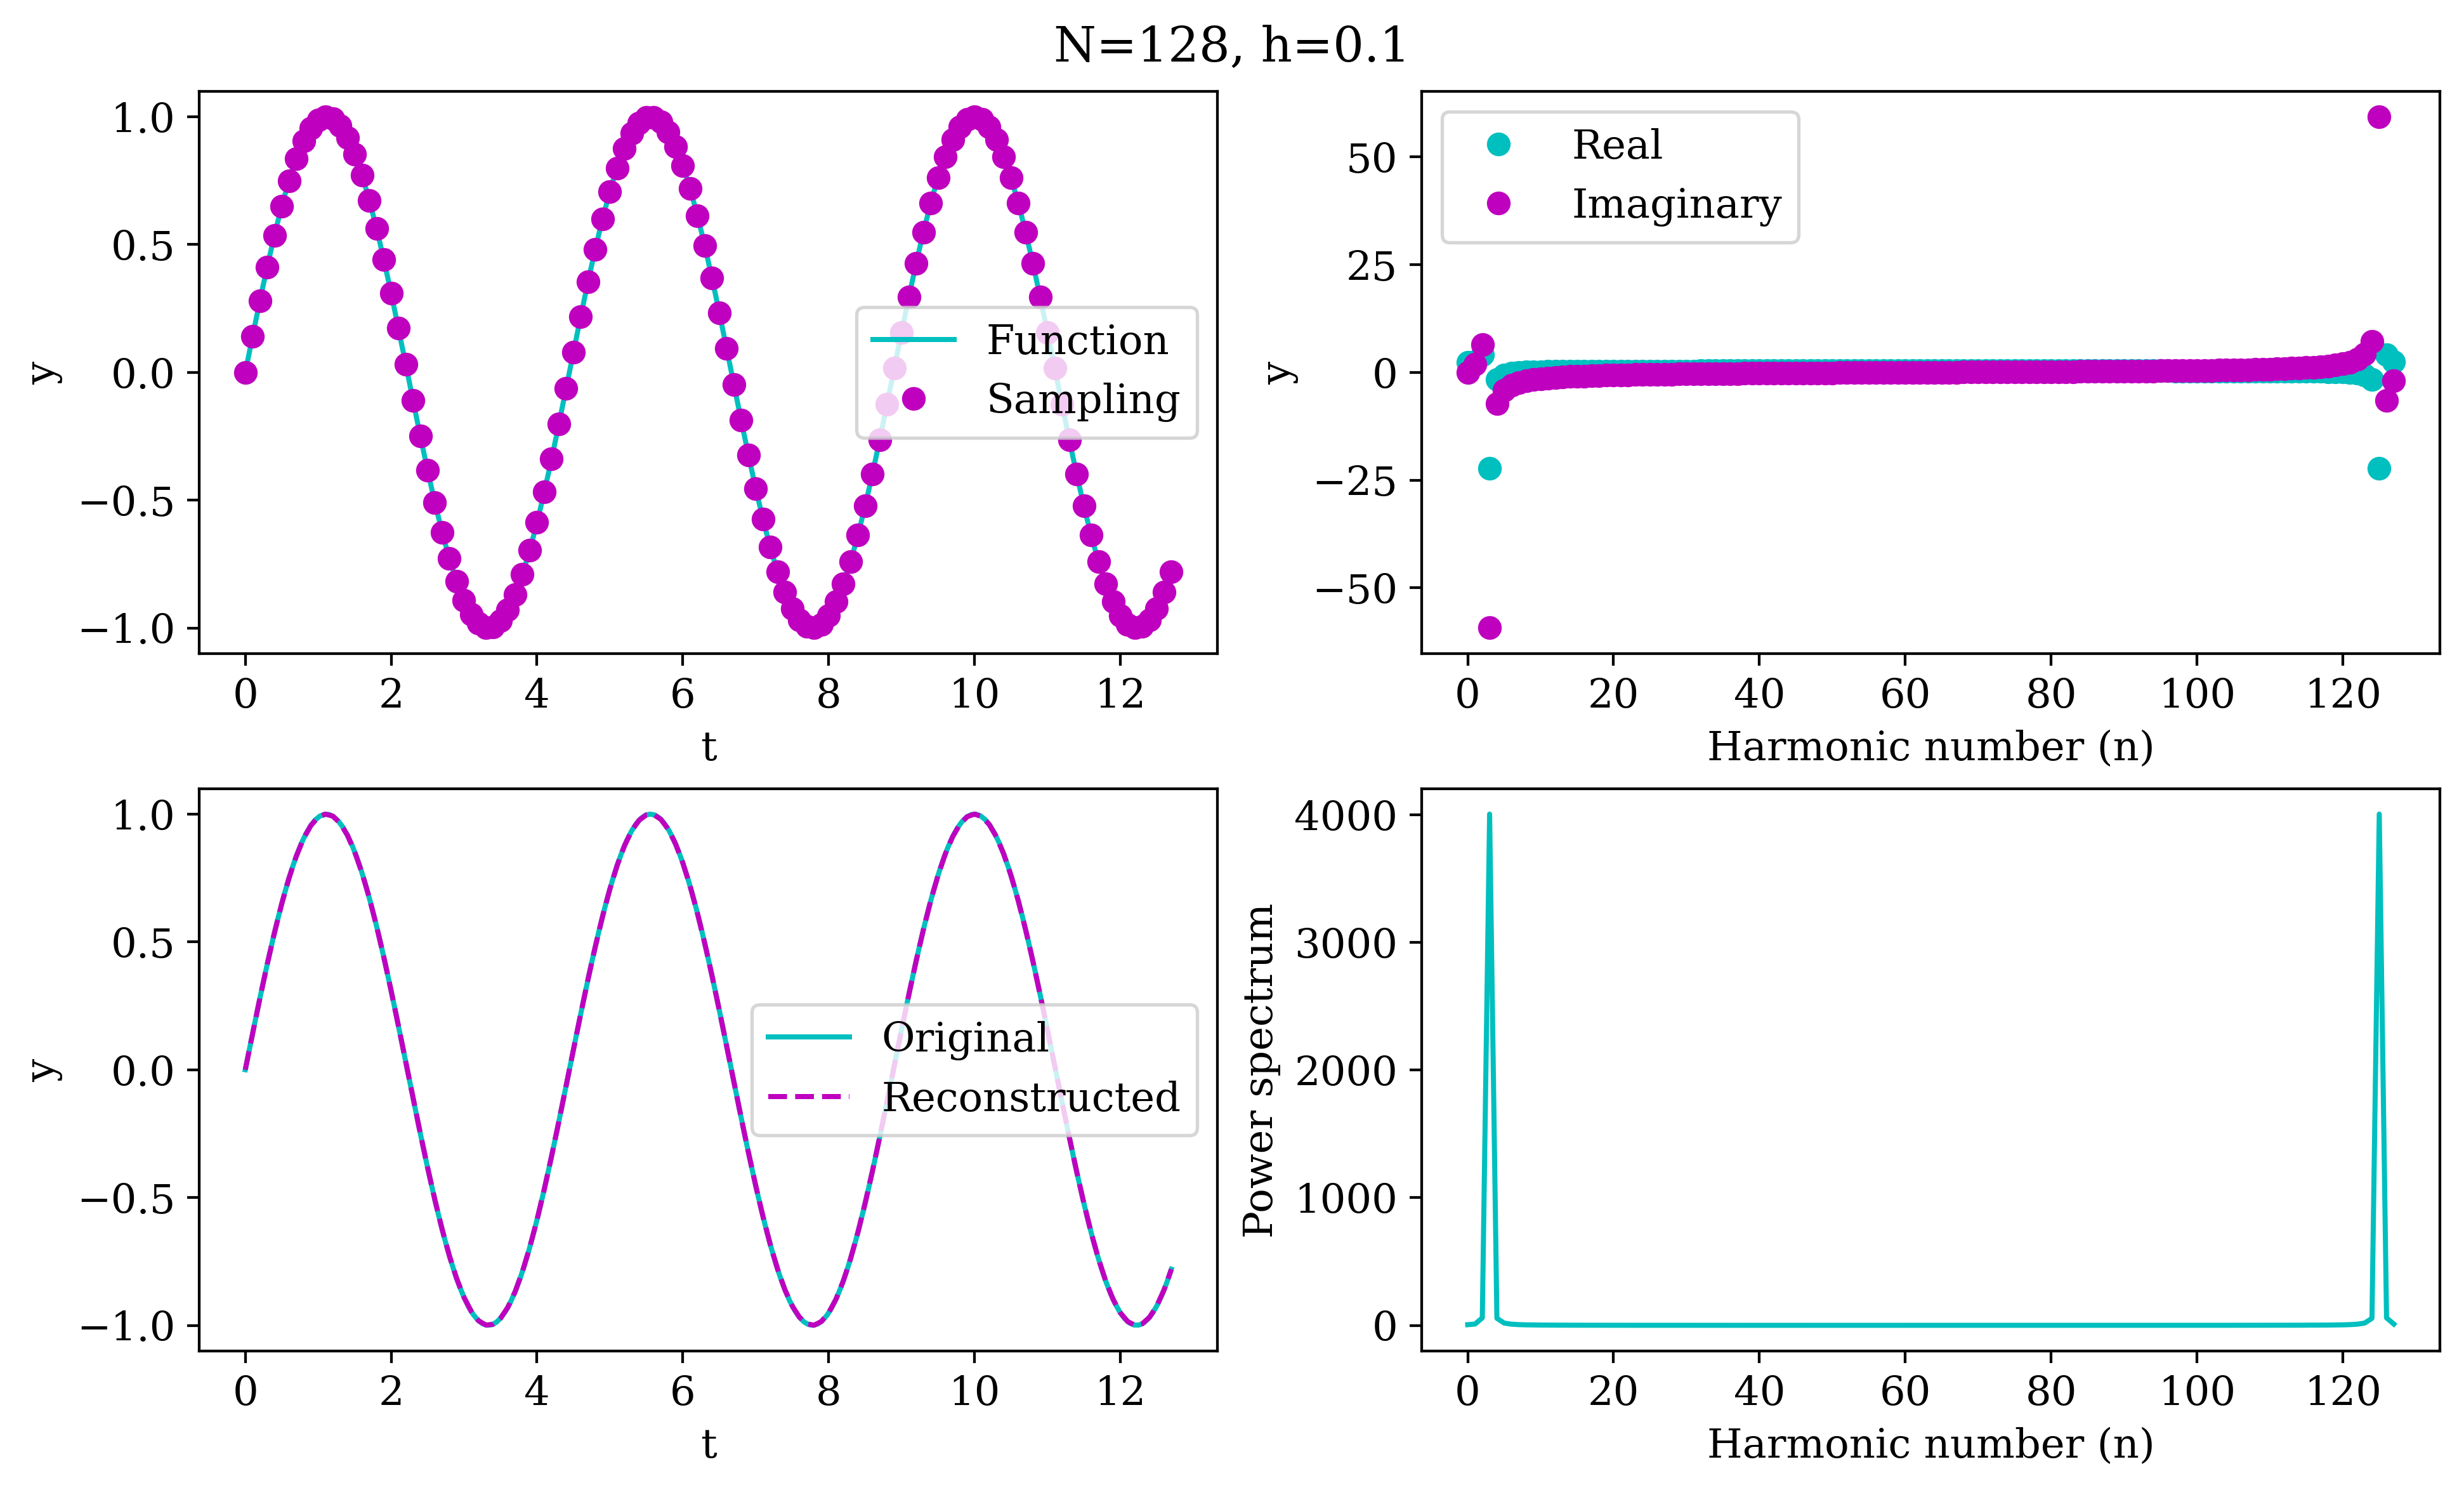

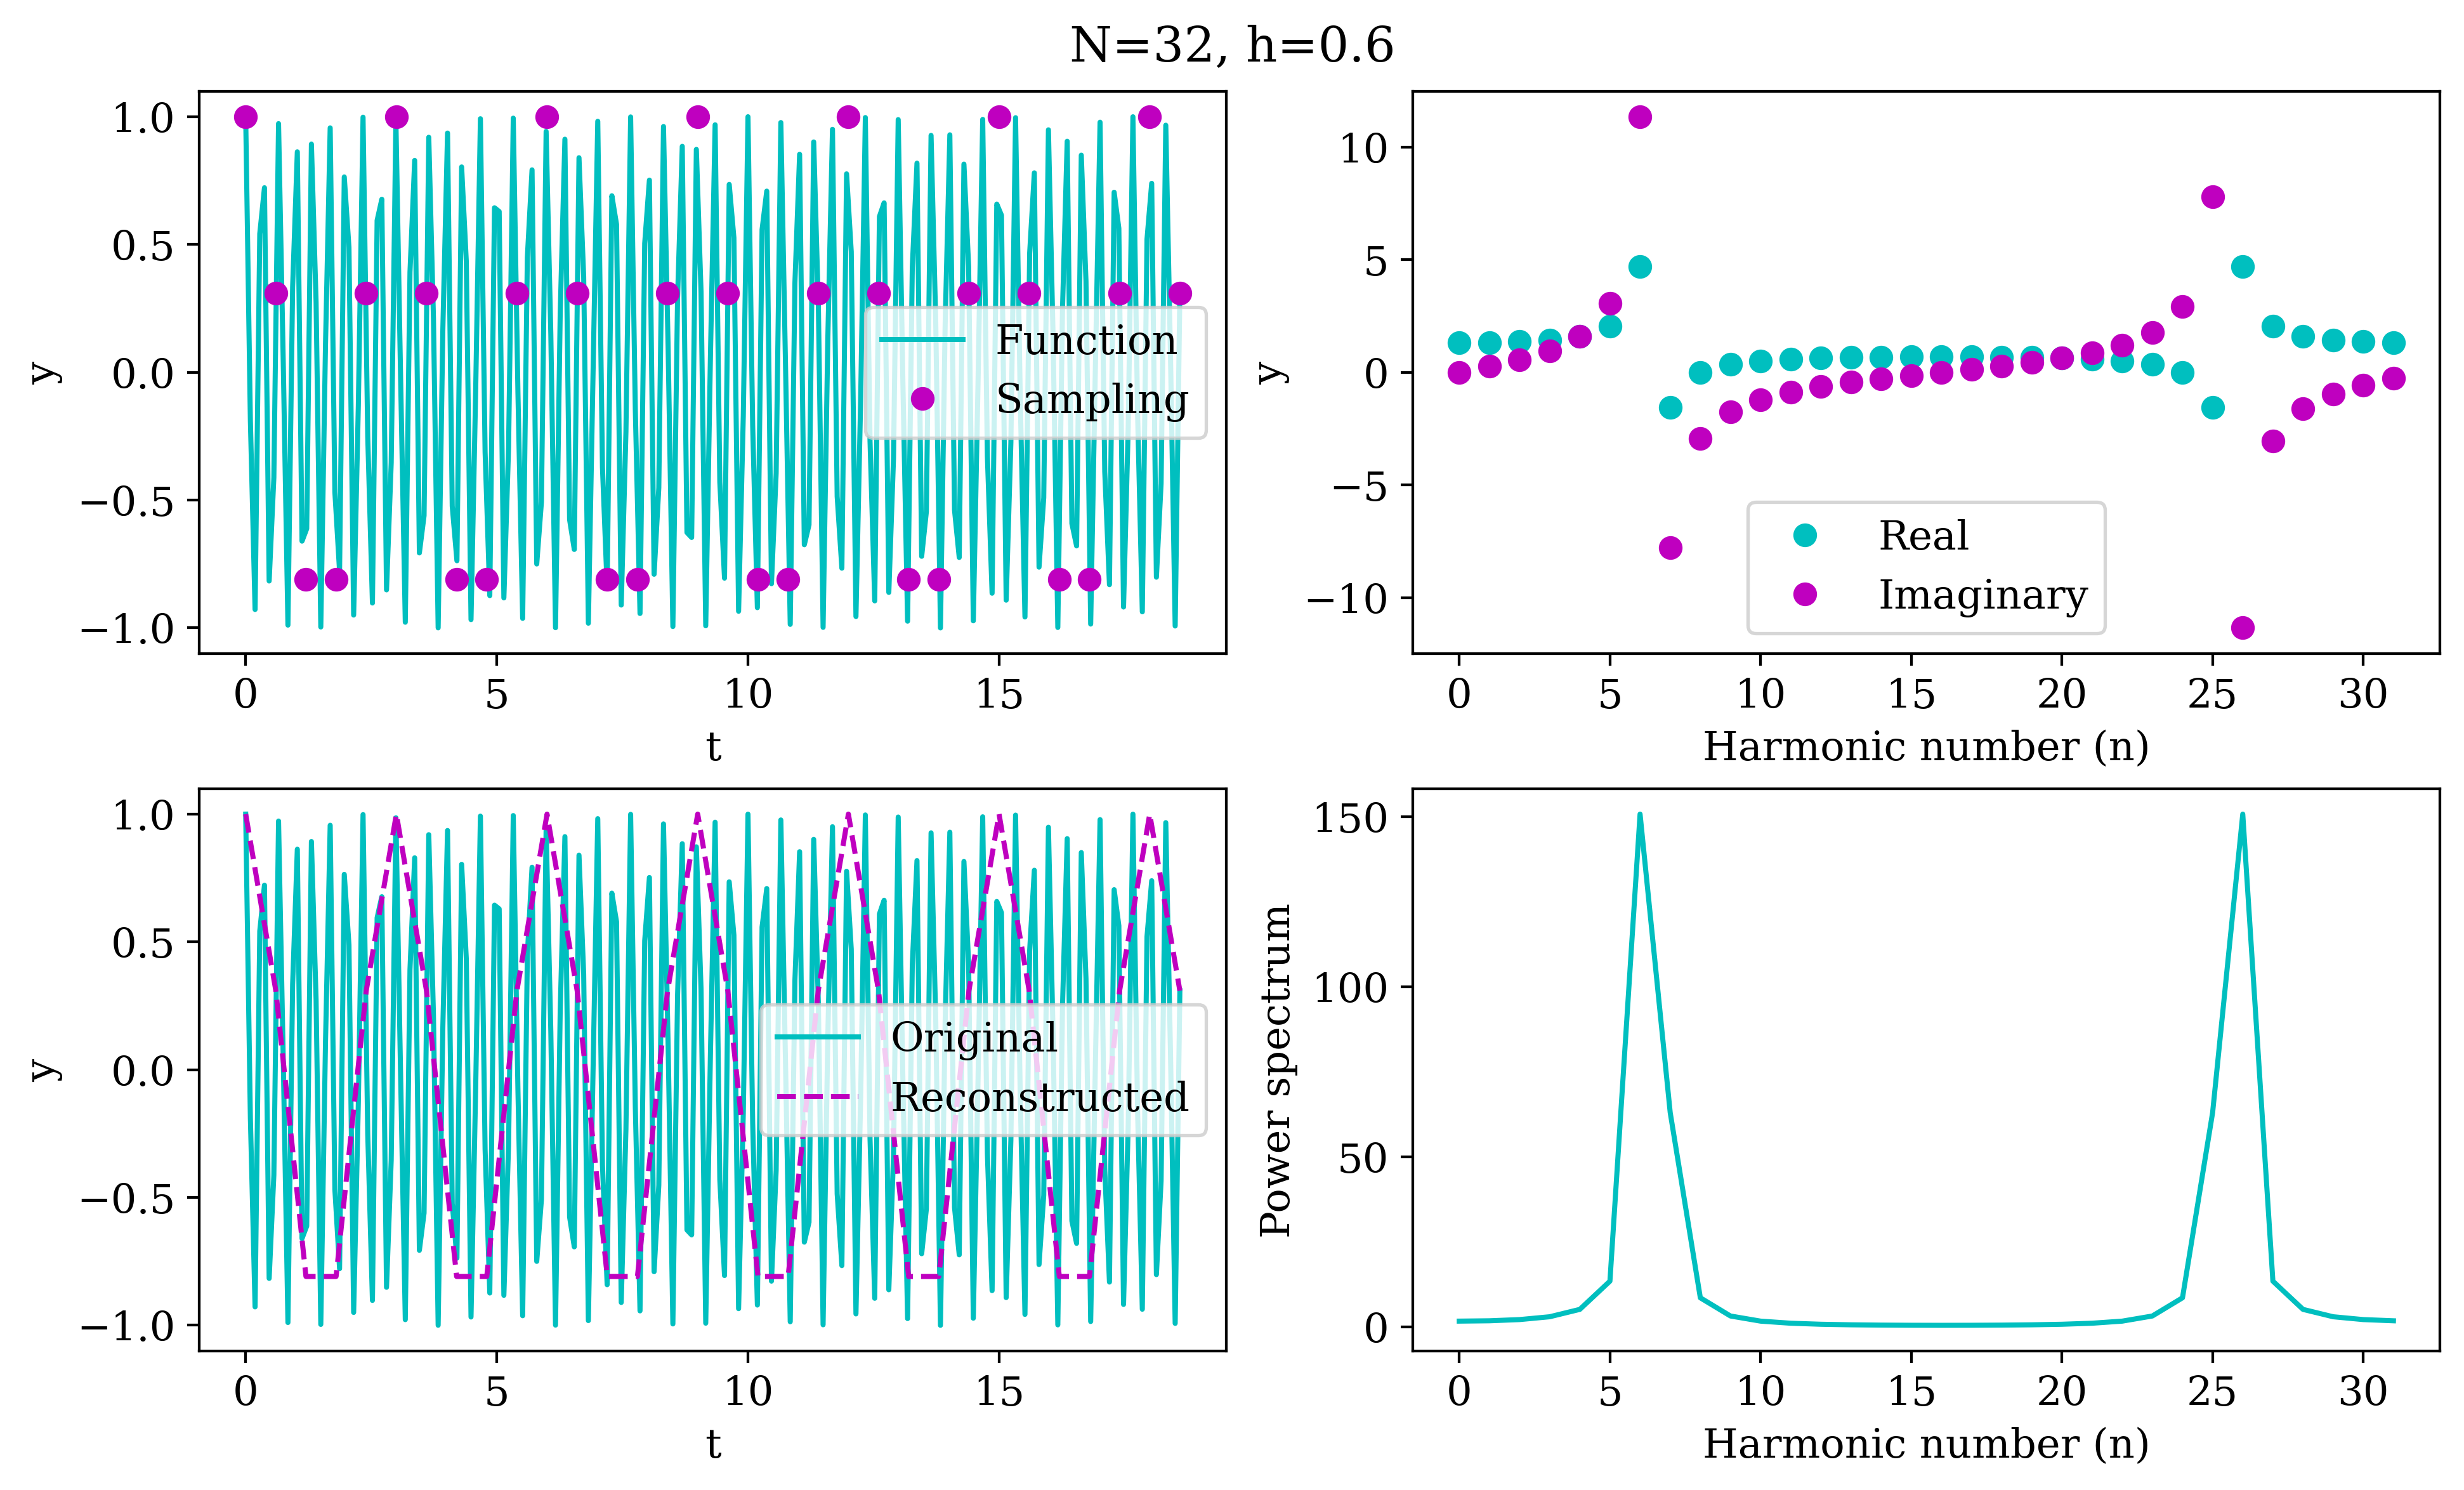

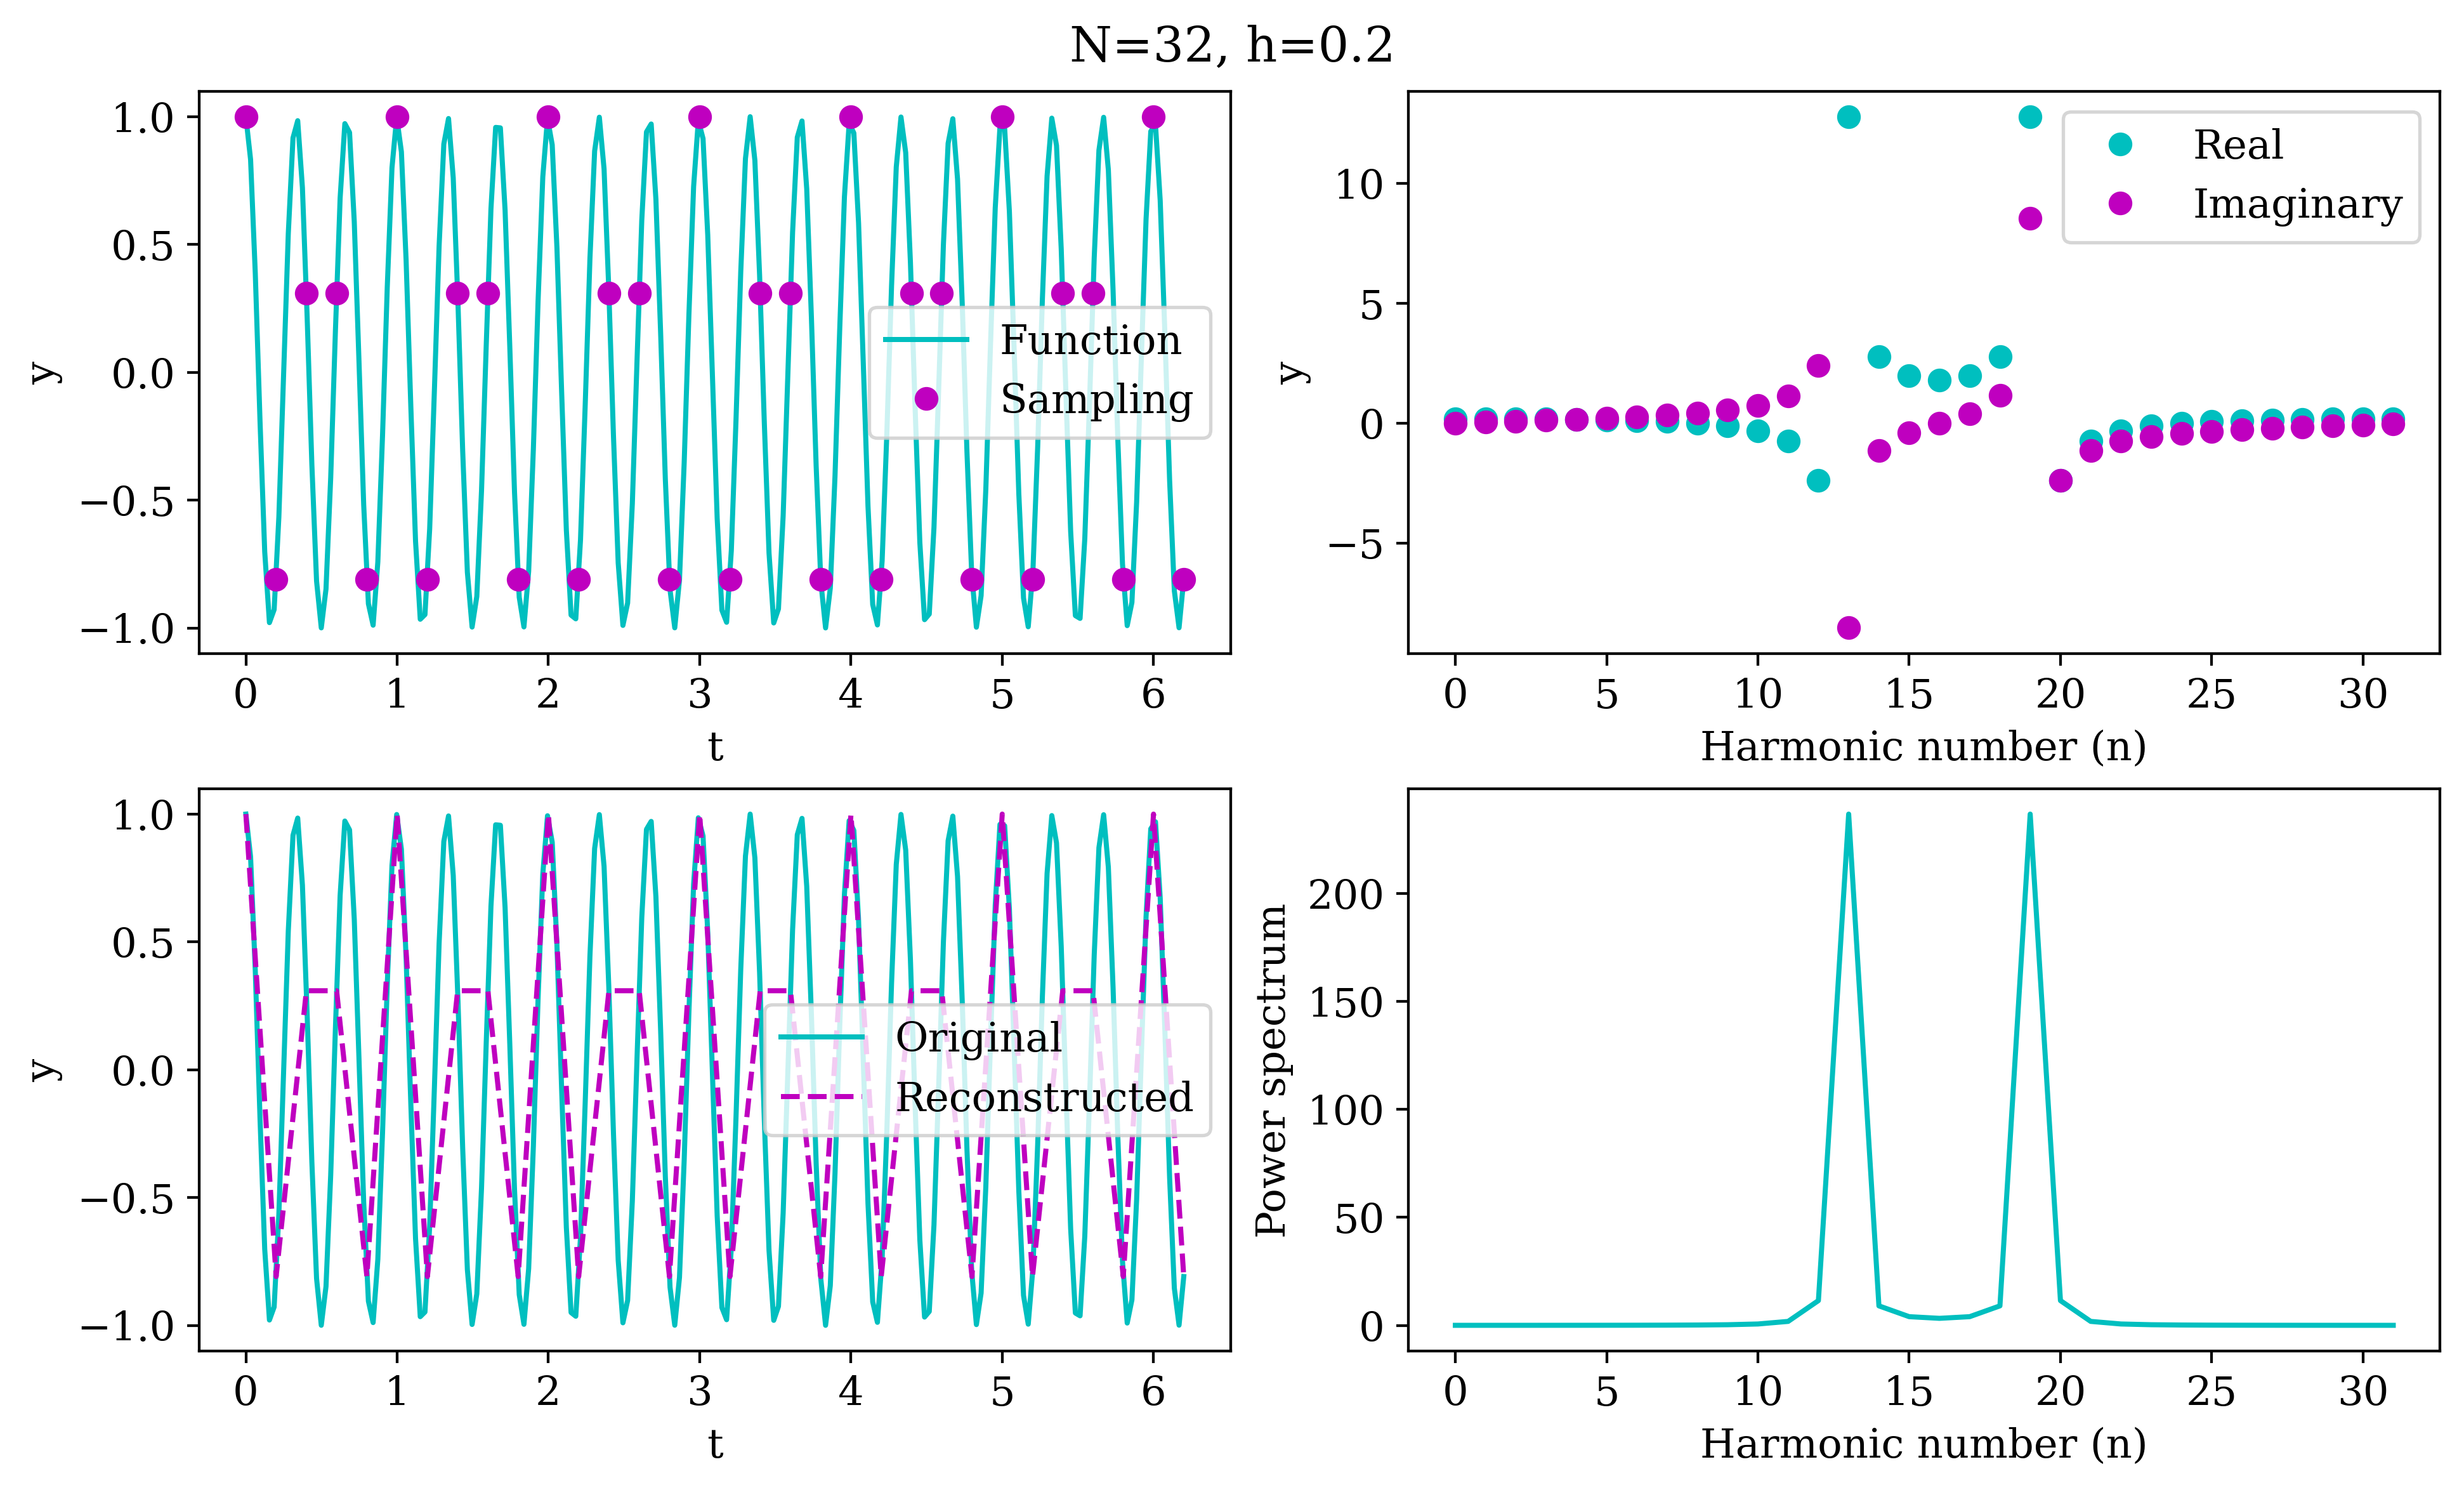

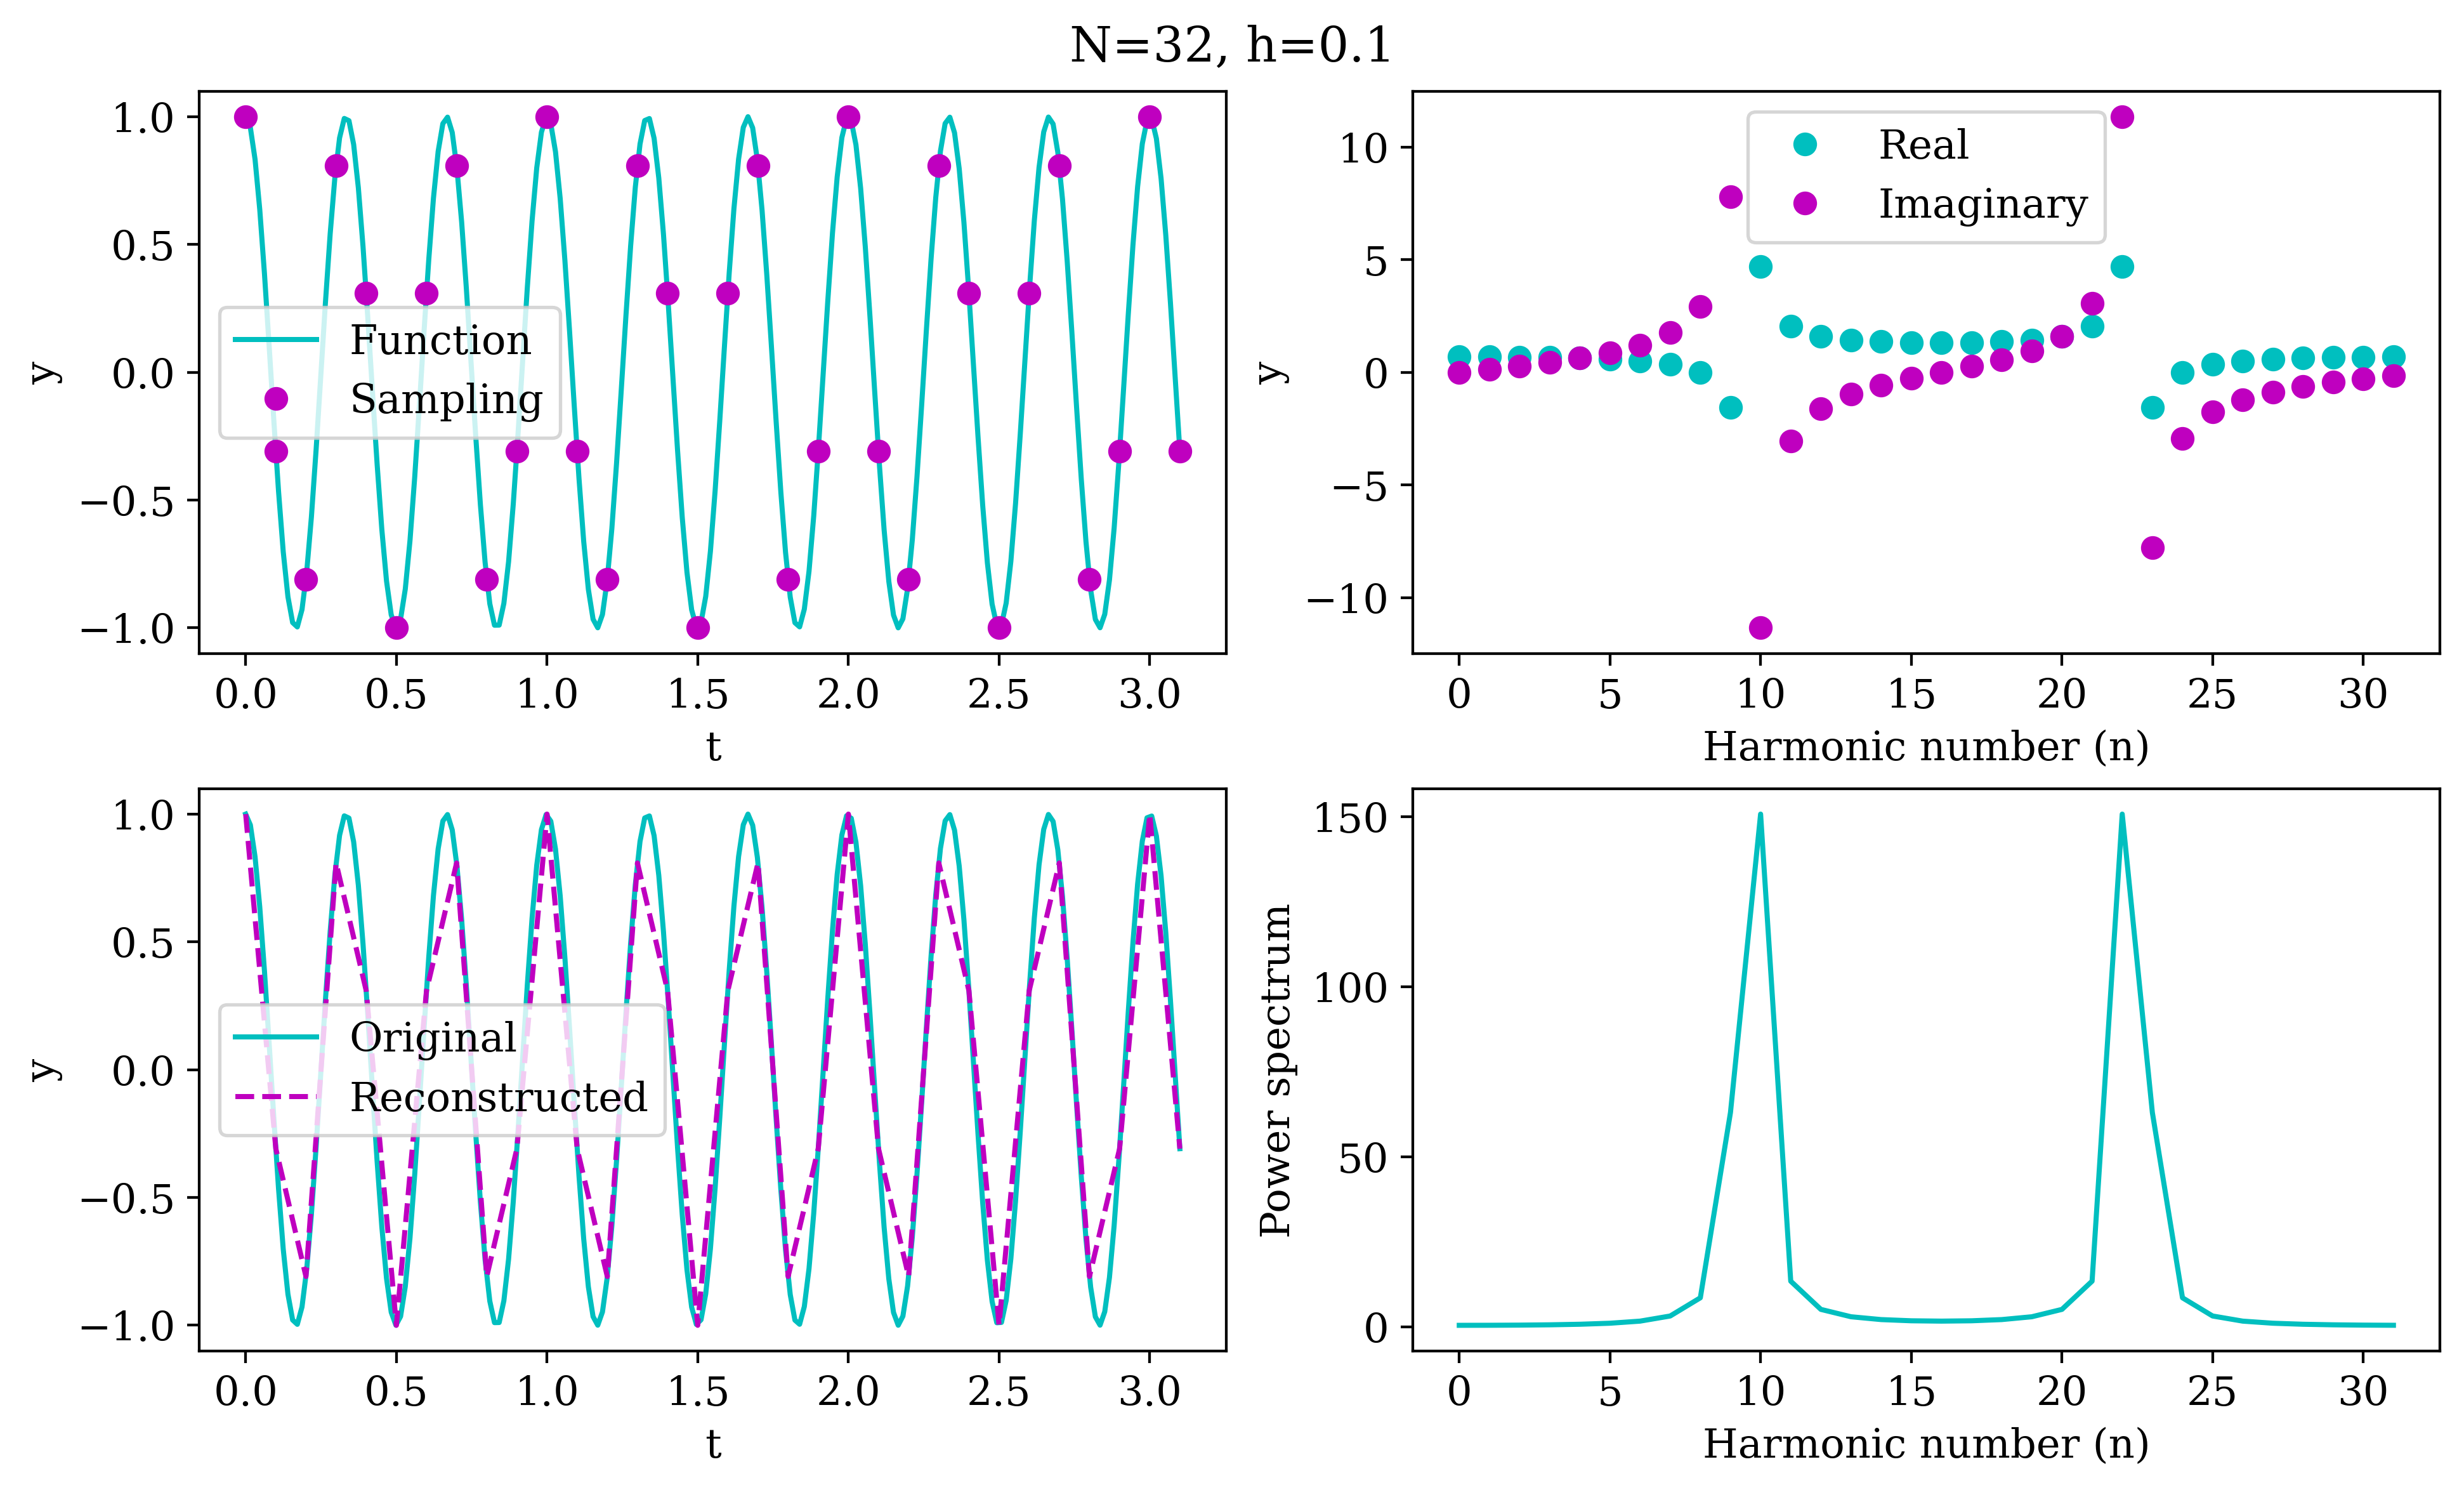

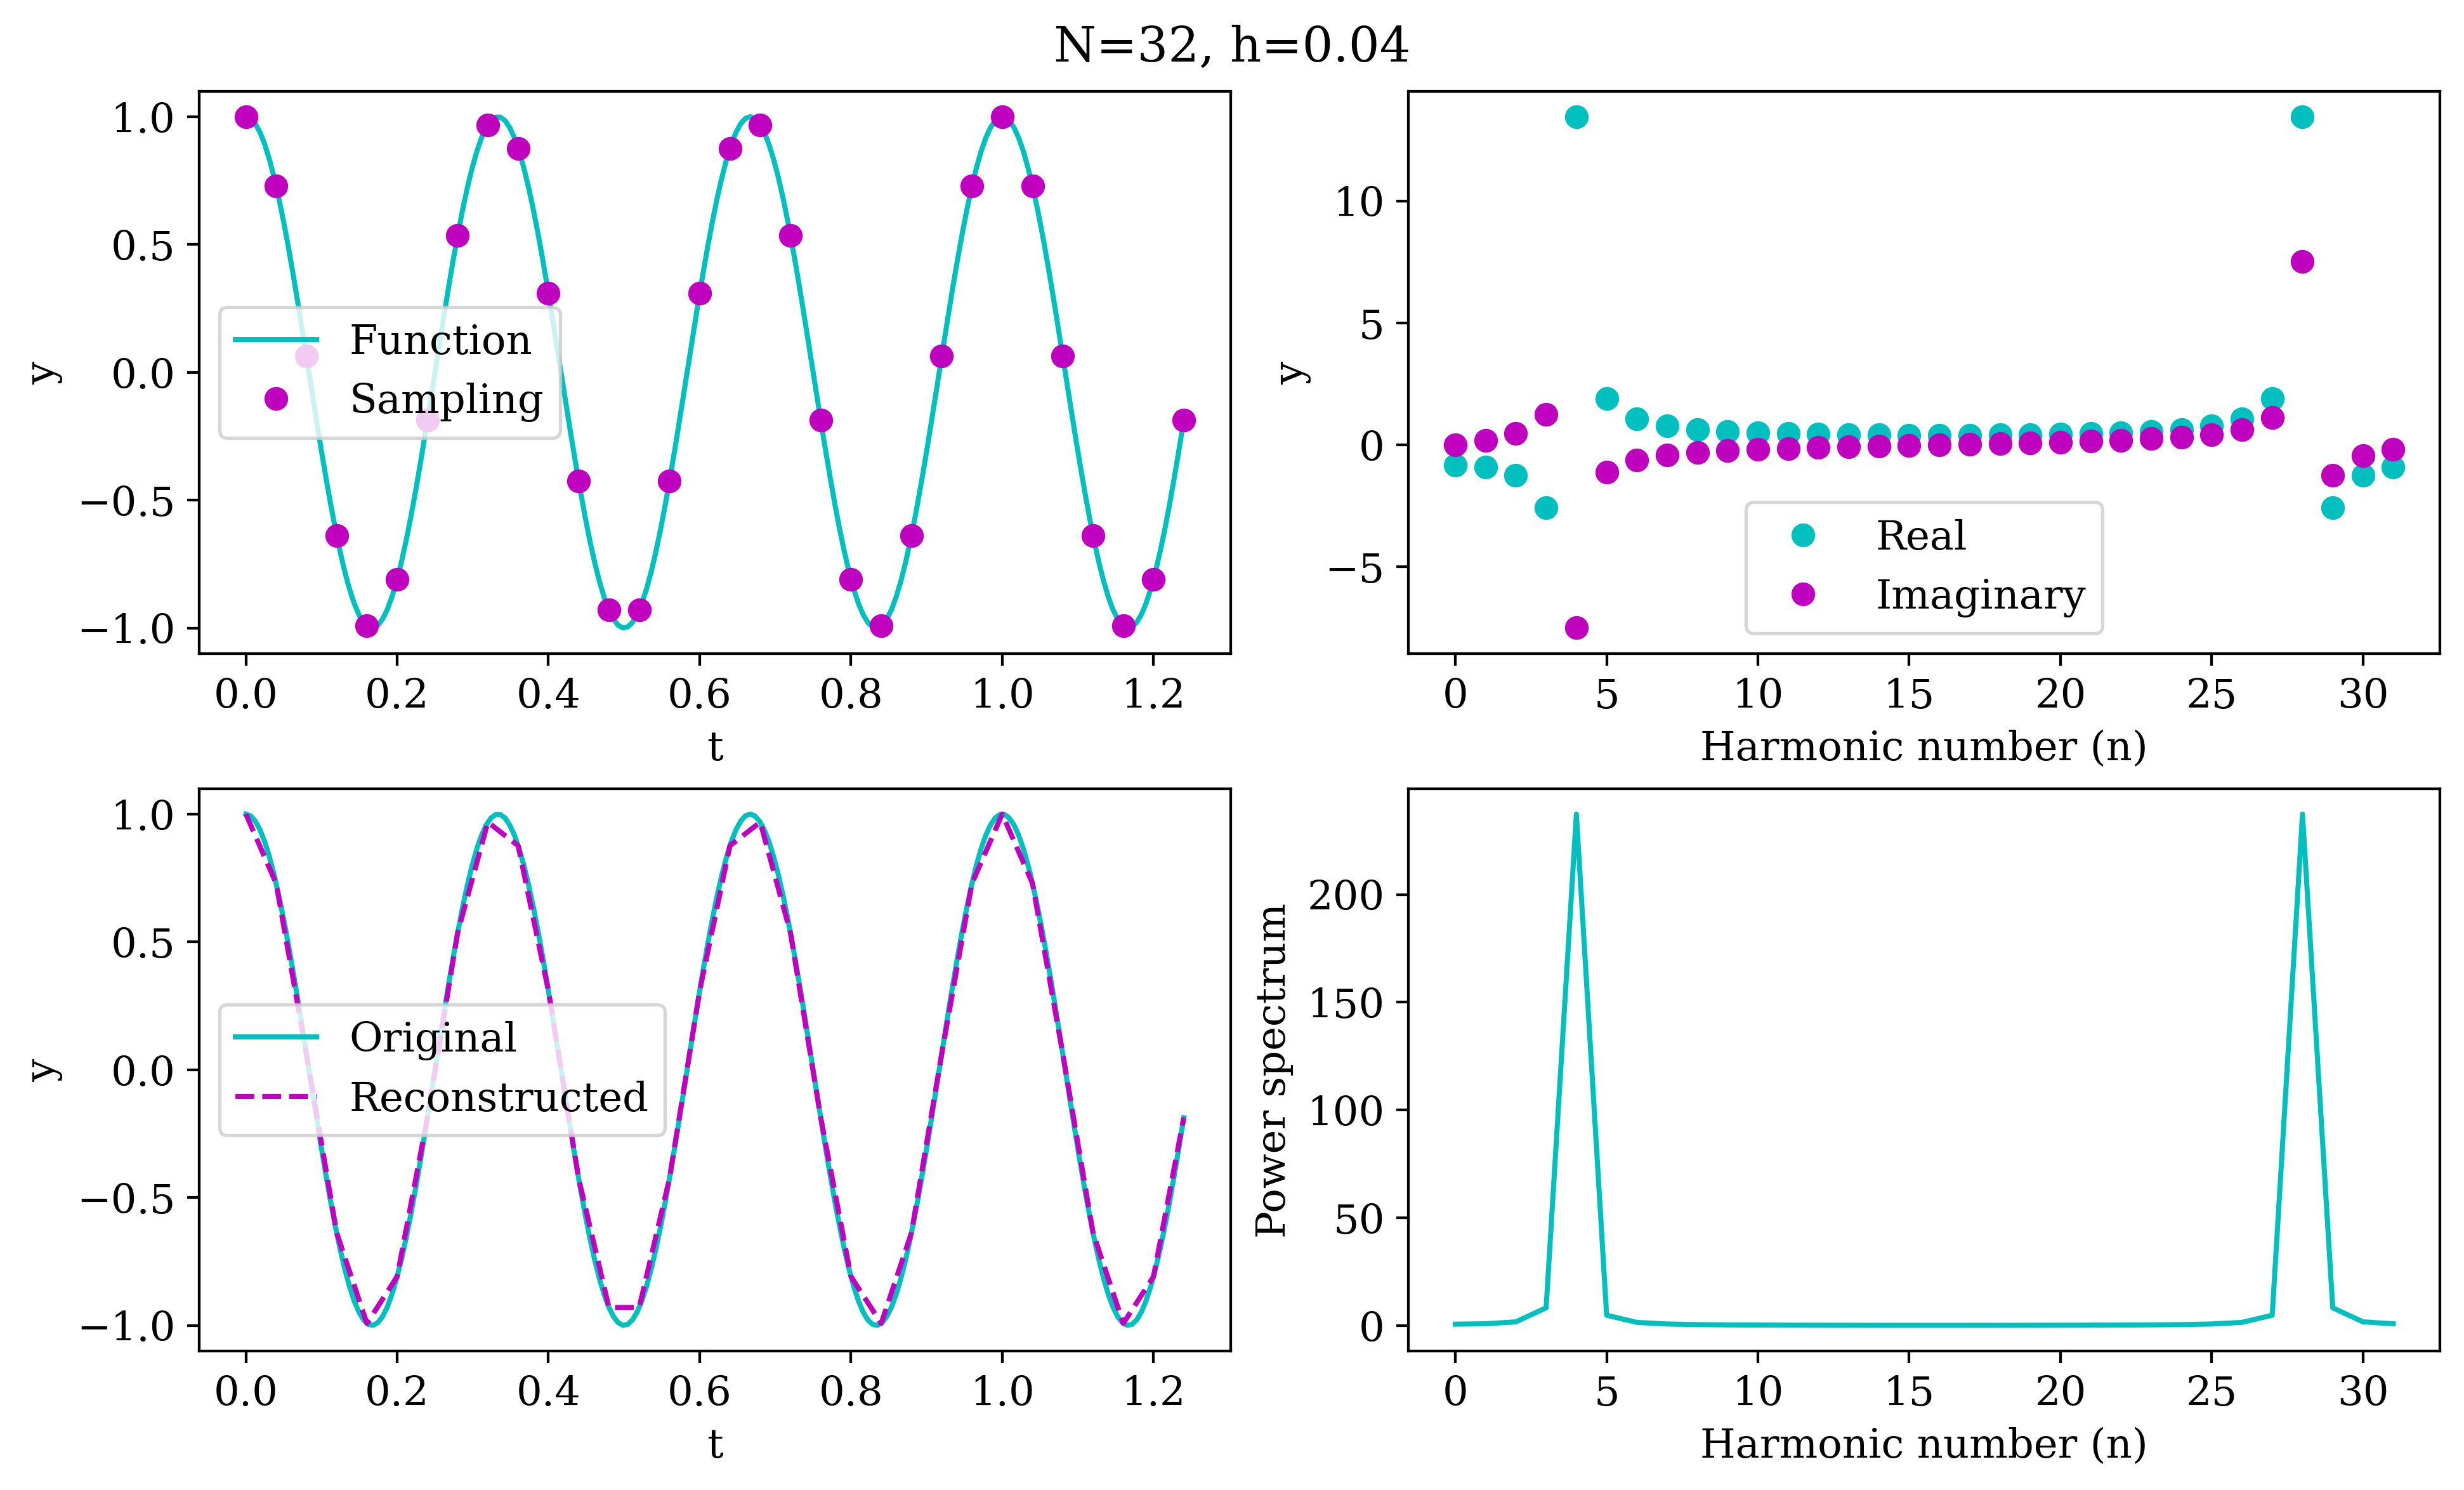

In [4]:
"""Real part of Discrete Fourier Transform

f - function to integrate
N - number of intervals
n - harmonic number
"""
def real(f, N, n):
  return sum(f(m) * np.cos(2 * np.pi * m * n / N) for m in range(N))


"""Imaginary part of Discrete Fourier Transform

f - function to integrate
N - number of intervals
n - harmonic number
"""
def imag(f, N, n):
  return sum(-f(m) * np.sin(2 * np.pi * m * n / N) for m in range(N))


"""Reconstruct the real part of function f

f - function to be reconstructed
N - number of intervals
m - harmonic number
"""
def reconstruct(f, N, m):
  return (1 / N) * sum(real(f, N, n) * np.cos(2 * np.pi * m * n / N)
                       - imag(f, N, n) * np.sin(2 * np.pi * m * n / N)
                       for n in range(N))


"""Plot sampling points, real and imaginary parts of DFT, power spectrum
and reconstructed function F

F - function to be reconstructed
N - number of intervals
h - sampling interval
name - name of the plot
"""
def plot(F, N, h, name):
  ts = np.arange(N) * h
  ts_real = np.linspace(0, (N - 1) * h, num=200)

  fig, axs = plt.subplots(2, 2, figsize=(10, 6), constrained_layout=True,
                          dpi=384)
  plt.suptitle(f'N={N}, h={h}')

  axs[0,0].plot(ts_real, F(ts_real), label='Function', color='c')
  axs[0,0].plot(ts, F(ts), 'mo', label='Sampling')
  axs[0,0].legend()
  axs[0,0].set_xlabel('t')
  axs[0,0].set_ylabel('y')

  f = lambda m: F(m * h)
  ns = np.arange(N)

  real_values = np.array([real(f, N, n) for n in range(N)])
  imag_values = np.array([imag(f, N, n) for n in range(N)])

  axs[0,1].plot(ns, real_values, 'co', label='Real')
  axs[0,1].plot(ns, imag_values, 'mo', label='Imaginary')
  axs[0,1].legend()
  axs[0,1].set_xlabel('Harmonic number (n)')
  axs[0,1].set_ylabel('y')

  axs[1,0].plot(ts_real, F(ts_real), label='Original', color='c')
  axs[1,0].plot(ts, [reconstruct(f, N, m) for m in range(N)], 'm--',
                label='Reconstructed')
  axs[1,0].legend()
  axs[1,0].set_xlabel('t')
  axs[1,0].set_ylabel('y')

  P = real_values**2 + imag_values**2

  axs[1,1].plot(ns, P, color='c')
  axs[1,1].set_xlabel('Harmonic number (n)')
  axs[1,1].set_ylabel('Power spectrum')

  plt.savefig(f'{name}.png', bbox_inches='tight')
  plt.show()


h, N = 0.1, 128
r = 1 / h
v1 = 1 / (N * h)

print(f'r={r}, v1={v1}\n')

F = lambda t: np.sin(0.45 * np.pi * t)
plot(F, N, h, 'sin')

F = lambda t: np.cos(6 * np.pi * t)
N = 32
hs = [0.6, 0.2, 0.1, 0.04]

for h in hs:
  plot(F, N, h, f'cos_{h}')